# Retinal Disease Detection Using Deep Learning on OCT Images
## Step 1: Dataset Collection and Understanding

**Goals**
- Obtain the OCT2017 retinal image dataset from Hugging Face
- Understand its structure, image formats, labels and class distribution
- Identify the four categories: **CNV, DME, DRUSEN, NORMAL**
- Count the images available in each category

**Class meanings**
| Class   | Description |
|---|---  |
| CNV     | Choroidal Neovascularization: abnormal vessel growth under the retina, with fluid/membrane |
| DME     | Diabetic Macular Edema: retinal thickening and fluid from diabetes |
| DRUSEN  | Yellow deposits under the retina, an early sign of AMD |
| NORMAL  | Healthy retina with preserved foveal contour |

**Reference (original Kermany et al. 2018 release):
** ~84,484 train images (CNV 37,205 / DME 11,348 / DRUSEN 8,616 / NORMAL 26,315) and 968 test images (250 per class, 242 in the Mendeley version).
Hugging Face mirrors may be full copies or subsets, so the counts you see below depend on the mirror you load.

In [ ]:
import os
os.environ["HF_HUB_DISABLE_XET"] = "1"
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
os.environ["HF_HUB_DISABLE_SYMLINKS_WARNING"] = "1"

In [ ]:
!pip install -q datasets pillow matplotlib seaborn pandas numpy

In [ ]:
import random
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datasets import load_dataset, DatasetDict, ClassLabel

sns.set_style("whitegrid")
random.seed(42)
np.random.seed(42)

In [ ]:
### 1.1 Load the dataset from Hugging Face
Set `DATASET_ID` to the OCT2017 mirror you want. The default below is a small public mirror (good for quick testing). If you have a full-size OCT2017 mirror on the Hub, put its ID here instead; nothing else in the notebook needs to change.

In [ ]:
DATASET_ID = "Augusto777/OCT2017"   # change to a full OCT2017 mirror for the complete ~84k images
EXPECTED_CLASSES = ["CNV", "DME", "DRUSEN", "NORMAL"]

ds = load_dataset(DATASET_ID)
if not isinstance(ds, DatasetDict):           # single split -> wrap
    ds = DatasetDict({"train": ds})
print(ds)

Generating train split:   0%|          | 0/480 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['image', 'label'],
        num_rows: 480
    })
})


### 1.2 Dataset structure: splits, features, formats

In [ ]:
for split, d in ds.items():
    print(f"Split: {split:<12} rows: {len(d):,}")
    print("  columns :", d.column_names)
    print("  features:", d.features)
    print()

first_split = list(ds.keys())[0]
sample = ds[first_split][0]
print("Example record keys:", list(sample.keys()))
print("Image type:", type(sample["image"]))

Split: train        rows: 480
  columns : ['image', 'label']
  features: {'image': Image(mode=None, decode=True), 'label': ClassLabel(names=['CNV', 'DME', 'DRUSEN', 'NORMAL'])}

Example record keys: ['image', 'label']
Image type: <class 'PIL.JpegImagePlugin.JpegImageFile'>


### 1.3 Label mapping

In [ ]:
label_feat = ds[first_split].features["label"]
if isinstance(label_feat, ClassLabel):
    CLASS_NAMES = [n.upper() for n in label_feat.names]
else:
    CLASS_NAMES = EXPECTED_CLASSES
    print("Label has no names; assuming order:", CLASS_NAMES)

id2label = {i: n for i, n in enumerate(CLASS_NAMES)}
label2id = {n: i for i, n in id2label.items()}
print("id2label:", id2label)
print("Matches expected 4 classes:", set(CLASS_NAMES) == set(EXPECTED_CLASSES))

id2label: {0: 'CNV', 1: 'DME', 2: 'DRUSEN', 3: 'NORMAL'}
Matches expected 4 classes: True


### 1.4 Class distribution (images per category)

In [ ]:
rows = []
for split, d in ds.items():
    cnt = Counter(d["label"])
    for i, name in id2label.items():
        rows.append({"split": split, "class": name, "count": cnt.get(i, 0)})
dist = pd.DataFrame(rows)

table = dist.pivot(index="class", columns="split", values="count").reindex(CLASS_NAMES)
table["total"] = table.sum(axis=1)
table["percent"] = (table["total"] / table["total"].sum() * 100).round(2)
print(table)
print("\nTotal images:", int(table["total"].sum()))

split   train  total  percent
class                        
CNV       120    120     25.0
DME       120    120     25.0
DRUSEN    120    120     25.0
NORMAL    120    120     25.0

Total images: 480


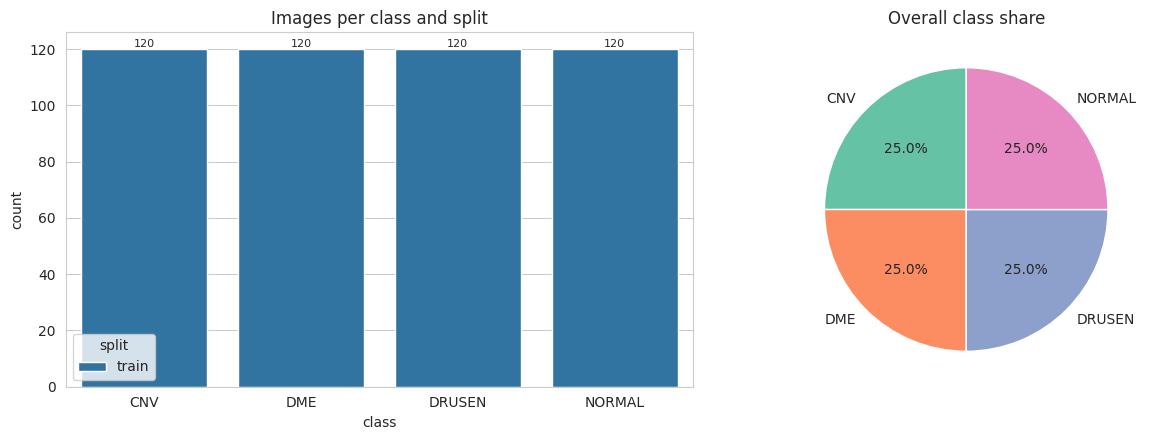

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.barplot(data=dist, x="class", y="count", hue="split", order=CLASS_NAMES, ax=axes[0])
axes[0].set_title("Images per class and split")
for c in axes[0].containers:
    axes[0].bar_label(c, fontsize=8)

totals = table["total"]
axes[1].pie(totals, labels=totals.index, autopct="%1.1f%%", startangle=90,
            colors=sns.color_palette("Set2", len(totals)))
axes[1].set_title("Overall class share")

plt.tight_layout()
plt.show()

### 1.5 Class imbalance check

In [ ]:
total = table["total"]
imbalance_ratio = total.max() / total.min()
print(f"Largest class : {total.idxmax()} ({int(total.max()):,})")
print(f"Smallest class: {total.idxmin()} ({int(total.min()):,})")
print(f"Imbalance ratio (max/min): {imbalance_ratio:.2f}")

# Inverse-frequency class weights, useful later for the weighted loss in PyTorch
weights = (total.sum() / (len(total) * total)).round(3)
print("\nSuggested class weights (inverse frequency):")
print(weights.to_string())

Largest class : CNV (120)
Smallest class: CNV (120)
Imbalance ratio (max/min): 1.00

Suggested class weights (inverse frequency):
class
CNV       1.0
DME       1.0
DRUSEN    1.0
NORMAL    1.0


### 1.6 Image properties: format, mode, size

In [ ]:
N = min(300, len(ds[first_split]))
idx = random.sample(range(len(ds[first_split])), N)

props = []
for i in idx:
    ex = ds[first_split][i]
    img = ex["image"]
    arr = np.array(img)
    props.append({
        "label": id2label[ex["label"]],
        "format": img.format,
        "mode": img.mode,
        "width": img.size[0],
        "height": img.size[1],
        "mean": arr.mean(),
        "std": arr.std(),
    })
props = pd.DataFrame(props)

print(f"Sampled {N} images from '{first_split}'")
print("\nFormats:", props["format"].value_counts(dropna=False).to_dict())
print("Modes  :", props["mode"].value_counts().to_dict())
print("\nSize summary:")
print(props[["width", "height"]].describe().round(1))
print("\nPixel stats by class:")
print(props.groupby("label")[["mean", "std"]].mean().round(2))

Sampled 300 images from 'train'

Formats: {'JPEG': 300}
Modes  : {'L': 300}

Size summary:
        width  height
count   300.0   300.0
mean    713.4   500.2
std     359.7     7.0
min     512.0   496.0
25%     512.0   496.0
50%     512.0   496.0
75%     768.0   512.0
max    1536.0   512.0

Pixel stats by class:
         mean    std
label               
CNV     46.53  46.48
DME     46.58  49.70
DRUSEN  51.68  54.65
NORMAL  44.15  49.18


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(props["width"], bins=30, color="steelblue");  axes[0].set_title("Image width (px)")
axes[1].hist(props["height"], bins=30, color="seagreen");  axes[1].set_title("Image height (px)")
sns.boxplot(data=props, x="label", y="mean", order=CLASS_NAMES, ax=axes[2])
axes[2].set_title("Mean pixel intensity by class")
plt.tight_layout()
plt.show()

### 1.7 Visual inspection: sample scans per class

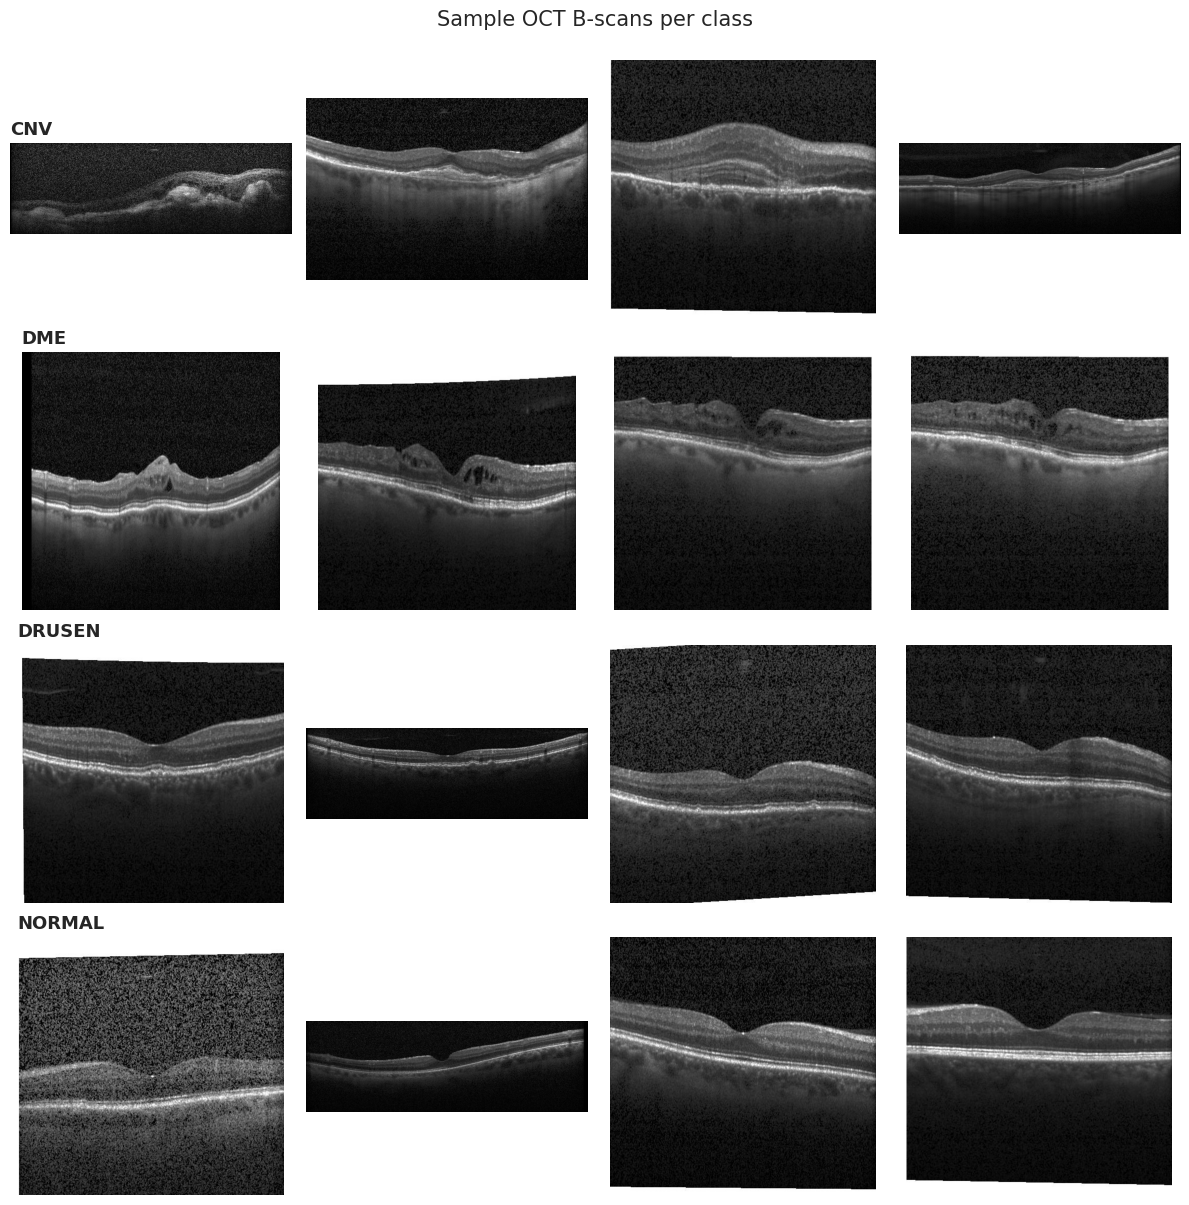

In [ ]:
PER_CLASS = 4
labels_arr = np.array(ds[first_split]["label"])

fig, axes = plt.subplots(len(CLASS_NAMES), PER_CLASS, figsize=(3 * PER_CLASS, 3 * len(CLASS_NAMES)))
for r, (cid, cname) in enumerate(id2label.items()):
    pool = np.where(labels_arr == cid)[0]
    pick = np.random.choice(pool, size=min(PER_CLASS, len(pool)), replace=False) if len(pool) else []
    for c in range(PER_CLASS):
        ax = axes[r, c]
        ax.axis("off")
        if c < len(pick):
            img = ds[first_split][int(pick[c])]["image"]
            ax.imshow(img, cmap="gray")
            if c == 0:
                ax.set_title(cname, loc="left", fontsize=13, fontweight="bold")
plt.suptitle("Sample OCT B-scans per class", y=1.0, fontsize=15)
plt.tight_layout()
plt.show()

### 1.8 Summary of findings
Fill in after running the notebook:
- **Splits available:** see section 1.2
- **Classes:** CNV, DME, DRUSEN, NORMAL (confirmed in 1.3)
- **Image format / mode / size:** see 1.6. OCT B-scans are grayscale and vary in size, so they will need resizing (e.g. 224x224) and 3-channel conversion for pretrained CNNs.
- **Class balance:** see 1.4 and 1.5. In the full dataset CNV dominates and DRUSEN is the smallest class, so use class weights or a weighted sampler, and report per-class metrics (precision, recall, F1), not just accuracy.

